# Minha carteira de 10 ações ganhou do Ibovespa e do CDI?

**Python Finance Lab · Aula 1** · *Finanças na prática, notebook por notebook.*

---

## Parte 1 · A pergunta

Imagine que, em 1º de outubro de 2021, você tinha R\\$ 2.000 para investir. Em vez de apostar tudo em uma empresa só, dividiu o dinheiro em partes iguais entre 10 ações de setores diferentes: R\\$ 200 em cada uma. Depois disso, não mexeu mais em nada.

Cinco anos depois, em 30 de setembro de 2026, valeu a pena? Para responder, não basta olhar quanto a carteira rendeu. É preciso comparar com as alternativas: o **Ibovespa**, que mostra quanto rendeu a bolsa brasileira como um todo, e o **CDI**, que mostra quanto rendeu a renda fixa, sem os sobe e desce da bolsa.

Neste notebook, vamos buscar os preços reais das ações e do Ibovespa na internet, buscar o CDI direto no Banco Central e colocar as três alternativas lado a lado, num gráfico e numa tabela.

| Ticker | Empresa | Setor |
|---|---|---|
| ITUB4 | Itaú Unibanco | Bancos |
| VALE3 | Vale | Mineração |
| PETR4 | Petrobras | Petróleo |
| WEGE3 | WEG | Bens de capital |
| ABEV3 | Ambev | Bebidas |
| EGIE3 | Engie Brasil | Energia elétrica |
| SUZB3 | Suzano | Celulose |
| RADL3 | Raia Drogasil | Farmácias |
| VIVT3 | Telefônica Brasil (Vivo) | Telecomunicações |
| TOTS3 | Totvs | Tecnologia |

*Conteúdo exclusivamente educacional. Não constitui recomendação de investimento. As ações foram escolhidas para fins didáticos, uma por setor.*

## Parte 2 · Conceitos

### Bloco 2 · O vocabulário da aula

**Ação e ticker.** Uma ação é um pedacinho de uma empresa. Na bolsa brasileira, a B3, cada ação tem um código, o *ticker*: ITUB4 é o Itaú, VALE3 é a Vale. O número no fim indica o tipo de ação: 3 é ordinária (dá direito a voto nas assembleias) e 4 é preferencial (tem preferência no recebimento de dividendos).

**Preço ajustado.** Quem tem ações também recebe, em dinheiro, parte do lucro das empresas: são os *proventos*, como os dividendos. Quando a empresa paga um provento, o preço da ação cai mais ou menos o mesmo valor, porque esse dinheiro saiu do caixa dela. Se olhássemos só o preço, pareceria que o acionista perdeu dinheiro, quando na verdade ele recebeu. O preço ajustado corrige isso: recalcula o histórico como se cada provento tivesse sido reinvestido na própria ação. Ele também corrige os desdobramentos, quando uma ação é dividida em várias ações mais baratas. É o preço certo para medir rentabilidade.

**Benchmark.** É a referência de comparação. Dizer que a carteira rendeu 30% não significa muito sozinho: se, no mesmo período, a bolsa inteira subiu 50%, a carteira foi mal. Vamos usar dois benchmarks.

**Ibovespa.** É o principal índice da bolsa brasileira: uma carteira teórica com as ações mais negociadas da B3, que funciona como a "média do mercado". É um índice de retorno total, ou seja, considera os proventos pagos pelas empresas. Por isso, é comparável aos nossos preços ajustados.

**CDI.** É a taxa de juros dos empréstimos de um dia entre bancos. Anda colada na Selic, a taxa básica de juros definida pelo Banco Central, e é a referência da renda fixa: quando um banco diz que um CDB rende "100% do CDI", é dessa taxa que ele está falando. O CDI rende um pouco a cada dia útil e nunca cai. Por isso, representa o que você ganharia sem correr o risco de oscilação da bolsa.

**Retorno acumulado.** É quanto o dinheiro cresceu no período inteiro. Se R\\$ 2.000 viraram R\\$ 2.600, o retorno foi de 30%.

**Juros compostos.** No CDI, o rendimento de hoje também rende amanhã. Por isso, as taxas diárias não são somadas: multiplicam-se os fatores de crescimento de cada dia.

## Parte 3 · Fórmulas

### Bloco 3 · As contas da aula

A aula inteira se apoia em três contas.

**1. Quanto R\\$ 1 virou em cada ação.** Se $P_0$ é o preço no primeiro dia e $P_t$ é o preço no dia $t$, cada real investido virou:

$$C_t = \frac{P_t}{P_0}$$

*Exemplo:* uma ação comprada a R\\$ 20 que hoje vale R\\$ 25 tem $C = 25 / 20 = 1{,}25$. Cada R\\$ 1 virou R\\$ 1,25, e os R\\$ 200 viraram R\\$ 250.

**2. Quanto vale a carteira.** O capital $K$ = R\\$ 2.000 foi dividido igualmente entre $N$ = 10 ações, e cada uma recebeu $K/N$ = R\\$ 200. O valor da carteira no dia $t$ é a soma das 10 partes, o que dá o mesmo que o capital vezes a média dos fatores:

$$V_t = \sum_{i=1}^{N} \frac{K}{N}\, C_{i,t} = K \cdot \frac{1}{N}\sum_{i=1}^{N} C_{i,t}$$

**3. Quanto rendeu o CDI.** O Banco Central publica a taxa de cada dia útil em % ao dia, que vamos chamar de $\text{cdi}_d$. O fator acumulado até o dia $t$ é o produto dos fatores diários:

$$F_t = \prod_{d=1}^{t}\left(1 + \frac{\text{cdi}_d}{100}\right)$$

*Exemplo:* três dias seguidos a 0,05% ao dia dão $1{,}0005 \times 1{,}0005 \times 1{,}0005 \approx 1{,}0015$, ou seja, cerca de 0,15% no total.

Em todos os casos, o **retorno no período** é o valor final dividido pelo inicial, menos 1:

$$R = \frac{V_{\text{final}}}{V_{\text{inicial}}} - 1$$

## Parte 4 · Implementação

### Bloco 4 · Instalar as bibliotecas

Uma biblioteca é um pacote de código pronto, escrito e compartilhado por outras pessoas. Em vez de programar do zero a conexão com o Yahoo Finance ou o desenho de um gráfico, usamos bibliotecas que já fazem isso. Precisamos de quatro:

- **yfinance:** baixa cotações do Yahoo Finance.
- **pandas:** organiza os dados em tabelas e faz contas com elas.
- **matplotlib:** desenha gráficos.
- **requests:** busca dados em endereços da internet, como a API do Banco Central.

O comando começa com `%pip`, e não com `!pip`, porque o `%pip` instala as bibliotecas exatamente no Python que está rodando este notebook. Basta rodar esta célula uma vez em cada computador.

> **O que esperar:** mensagens de instalação. Se as bibliotecas já estiverem instaladas, aparece "Requirement already satisfied". Depois de instalar pela primeira vez, pode ser preciso reiniciar o kernel (menu Kernel → Restart Kernel).

In [2]:
%pip install yfinance pandas matplotlib requests

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


### Bloco 5 · Importar as bibliotecas

Instalar deixa a biblioteca no computador; importar a carrega para dentro do notebook. O `as` dá um apelido curto a cada uma: em vez de escrever `pandas` toda vez, escrevemos `pd`. Os apelidos `yf`, `pd` e `plt` são uma convenção, e você vai encontrá-los em quase todo código de finanças em Python.

O que vem depois do `#` é um comentário. O Python ignora; ele serve só para quem lê o código.

> **O que esperar:** nada. Se não aparecer nenhuma mensagem de erro, deu certo.

In [3]:
import yfinance as yf            # baixa cotações do Yahoo Finance
import pandas as pd              # trabalha com tabelas (DataFrames)
import matplotlib.pyplot as plt  # desenha gráficos
import requests                  # conversa com a API do Banco Central

### Bloco 6 · As premissas da análise

Esta célula reúne todas as escolhas da análise: quais ações, qual período e quanto dinheiro. Deixar tudo num lugar só tem uma vantagem: para testar outra carteira ou outro período, você muda aqui e roda o notebook de novo, sem caçar números espalhados pelo código.

`ACOES` é uma **lista**: vários valores entre colchetes, separados por vírgula, numa ordem definida. Cada ticker termina em `.SA`, o sufixo que o Yahoo Finance usa para as ações da B3 (São Paulo). No Yahoo, o Ibovespa se chama `^BVSP`.

As datas estão no formato ano-mês-dia, o padrão internacional, que a maioria das bibliotecas entende.

Os nomes em letras maiúsculas seguem uma convenção do Python para valores que não mudam ao longo do notebook. O `print` no final confere a divisão do capital: `len(ACOES)` conta os itens da lista.

> **O que esperar:** `10 ações | R$ 200.0 em cada uma`. O Python escreve números decimais com ponto, no padrão americano: `200.0` é o mesmo que 200,0.

In [4]:
ACOES = [
    "ITUB4.SA",  # Itaú Unibanco: bancos
    "VALE3.SA",  # Vale: mineração
    "PETR4.SA",  # Petrobras: petróleo
    "WEGE3.SA",  # WEG: bens de capital
    "ABEV3.SA",  # Ambev: bebidas
    "EGIE3.SA",  # Engie Brasil: energia elétrica
    "SUZB3.SA",  # Suzano: celulose
    "RADL3.SA",  # Raia Drogasil: farmácias
    "VIVT3.SA",  # Telefônica Brasil (Vivo): telecom
    "TOTS3.SA",  # Totvs: tecnologia
]
INDICE = "^BVSP"           # Ibovespa
DATA_INICIO = "2021-10-01"
DATA_FIM = "2026-09-30"
CAPITAL = 2000             # R$ 2.000 no total, ou seja, R$ 200 em cada ação

print(len(ACOES), "ações | R$", CAPITAL / len(ACOES), "em cada uma")

10 ações | R$ 200.0 em cada uma


### Bloco 7 · Baixar os preços das 10 ações

A função `yf.download` busca no Yahoo Finance o histórico de todas as ações da lista de uma vez só. Pedimos os dados a partir da data de início e usamos `auto_adjust=True` para receber os preços já ajustados por proventos e desdobramentos. Esse já é o comportamento padrão da biblioteca, mas escrever explicitamente deixa claro o que estamos usando e protege o notebook se o padrão mudar numa versão futura. O `progress=False` só esconde a barra de progresso.

O resultado traz várias informações por dia: abertura, máxima, mínima, fechamento e volume. Ficamos só com o fechamento, `dados["Close"]`.

Depois, recortamos o período exato com `.loc[DATA_INICIO:DATA_FIM]`. O `.loc` seleciona linhas pelo rótulo, que aqui é a data. Com datas, o recorte inclui as duas pontas: o primeiro e o último dia entram.

Por fim, tiramos o `.SA` do nome das colunas, só para que tabelas e gráficos fiquem mais limpos.

O resultado é um **DataFrame**, a tabela do pandas: as datas ficam nas linhas e as ações, nas colunas.

> **O que esperar:** uma tabela com 10 colunas e pouco mais de 1.200 linhas, já que a B3 tem cerca de 250 pregões por ano. O Jupyter mostra só as primeiras e as últimas linhas, e as colunas aparecem em ordem alfabética, que é como o yfinance organiza o resultado. Se o download de alguma ação falhar, o yfinance escreve uma mensagem de erro com o nome dela; nesse caso, rode a célula de novo.

In [5]:
dados = yf.download(ACOES, start=DATA_INICIO, auto_adjust=True, progress=False)
precos = dados["Close"].loc[DATA_INICIO:DATA_FIM]
precos.columns = precos.columns.str.replace(".SA", "")
precos

Ticker,ABEV3,EGIE3,ITUB4,PETR4,RADL3,SUZB3,TOTS3,VALE3,VIVT3,WEGE3
Date,,,,,,,,,,
2021-10-01,11.612251,20.241545,19.045134,8.280454,20.430904,45.816040,34.050758,50.393932,15.537575,35.900959
2021-10-04,11.437345,20.220024,15.623815,8.514080,19.400633,44.811874,32.291271,49.924377,15.417912,34.658688
2021-10-05,11.543809,19.929556,16.002533,8.700392,19.461746,43.964882,31.300400,49.567253,15.646353,33.541531
2021-10-06,11.482973,20.107065,16.053883,8.469722,19.697485,43.388577,30.883682,50.962681,15.526693,33.523647
2021-10-07,11.467763,20.021000,15.713681,8.457894,20.142778,43.161552,30.902199,52.483749,15.664483,33.568336
...,...,...,...,...,...,...,...,...,...,...
2026-09-24,15.340000,29.000000,41.852806,49.259998,18.450001,45.580002,35.130001,70.660004,30.251976,50.740002
2026-09-25,15.320000,29.100000,42.112701,48.070000,18.160000,45.000000,34.900002,70.769997,29.953535,51.070000
2026-09-28,15.200000,28.870001,41.692871,48.720001,17.670000,44.689999,33.980000,71.160004,29.510000,50.119999


### Bloco 8 · Olhar os dados antes de usar

Antes de fazer qualquer conta, olhamos os dados. Parece burocracia, mas é aqui que aparecem os problemas: uma ação que veio vazia, um período mais curto do que o pedido, dias sem preço.

- `precos.shape` mostra o tamanho da tabela: (linhas, colunas).
- `precos.index` é o **índice**, a coluna de datas que identifica cada linha. O `[0]` pega o primeiro elemento, e o `[-1]`, o último. Em Python, a contagem começa em zero, e os números negativos contam de trás para a frente. O `.date()` mostra só a data, sem o horário.
- `precos.isna()` marca cada célula vazia como verdadeira, e o `.sum()` conta quantas há em cada coluna. Uma célula vazia aparece na tabela como `NaN`, de *not a number* ("não é um número").

> **O que esperar:** o tamanho da tabela, o primeiro dia (2021-10-01), o último (2026-09-30) e a contagem de dias sem preço de cada ação. O esperado é zero, ou quase zero, em todas. Dois sinais de problema: **uma ação com todos os dias vazios** (o download dela falhou: rode o bloco 7 de novo) e **uma ação sem preço na primeira linha** da tabela do bloco 7 (ela não tem preço de compra no primeiro dia: escolha outra data de início).

In [6]:
print("Linhas e colunas:", precos.shape)
print("Primeiro dia:", precos.index[0].date())
print("Último dia:  ", precos.index[-1].date())
print()
print("Dias sem preço em cada ação:")
print(precos.isna().sum())

Linhas e colunas: (1247, 10)
Primeiro dia: 2021-10-01
Último dia:   2026-09-30

Dias sem preço em cada ação:
Ticker
ABEV3    0
EGIE3    0
ITUB4    0
PETR4    0
RADL3    0
SUZB3    0
TOTS3    0
VALE3    0
VIVT3    0
WEGE3    0
dtype: int64


### Bloco 9 · Tratar os dias sem preço

Se uma ação ficou sem preço em algum dia, por falha nos dados ou porque não foi negociada, a melhor estimativa do valor dela nesse dia é o último preço conhecido. É o que faz o `ffill()`, de *forward fill* ("preencher para a frente"): copia o último valor válido para os dias vazios seguintes.

Por que não simplesmente ignorar o dia vazio? Porque, mais adiante, vamos calcular a média das 10 ações para obter o valor da carteira. Se uma delas estivesse vazia num dia, o pandas calcularia a média só das outras 9, e a carteira daria um salto que não aconteceu.

Repare que escrevemos `precos = precos.ffill()`: a tabela tratada substitui a antiga.

> **O que esperar:** `Dias sem preço depois do ffill: 0`. O primeiro `.sum()` conta por ação; o segundo soma as 10 contagens.

In [7]:
precos = precos.ffill()
print("Dias sem preço depois do ffill:", precos.isna().sum().sum())

Dias sem preço depois do ffill: 0


### Bloco 10 · Baixar o Ibovespa

Agora, o primeiro benchmark. O processo é o mesmo das ações, com o código `^BVSP`. Como é um ticker só, usamos `multi_level_index=False`: assim, as colunas vêm com nomes simples (Close, High, Low…), e `dados_ibov["Close"]` devolve direto a série de fechamentos.

O resultado agora é uma **Series**: uma coluna só, com as datas no índice. O DataFrame é a tabela; a Series é uma coluna dela.

O Ibovespa é medido em pontos, não em reais. Não tem problema: daqui a pouco, vamos transformar tudo em "quanto R\\$ 2.000 viraram".

> **O que esperar:** a série do Ibovespa em pontos, com as mesmas datas das ações e a indicação `Name: Close` no rodapé.

In [8]:
dados_ibov = yf.download(
    INDICE, start=DATA_INICIO, auto_adjust=True, progress=False, multi_level_index=False
)
ibov = dados_ibov["Close"].loc[DATA_INICIO:DATA_FIM]
ibov

Date
2021-10-01    112900.0
2021-10-04    110393.0
2021-10-05    110458.0
2021-10-06    110560.0
2021-10-07    110585.0
                ...   
2026-09-24    183966.0
2026-09-25    183477.0
2026-09-28    182991.0
2026-09-29    183828.0
2026-09-30    186340.0
Name: Close, Length: 1247, dtype: float64

### Bloco 11 · Buscar o CDI no Banco Central

O CDI não está no Yahoo Finance. Vamos buscá-lo na fonte oficial: o SGS, Sistema Gerenciador de Séries Temporais do Banco Central, que publica milhares de séries econômicas numeradas. O CDI diário é a **série 12**, em % ao dia.

O acesso é feito por uma **API**: um endereço da internet que, em vez de devolver uma página para pessoas lerem, devolve dados para programas usarem. Montamos esse endereço com o número da série e as datas de início e fim. O Banco Central usa datas no formato brasileiro, dia/mês/ano, por isso convertemos as datas das premissas com `strftime("%d/%m/%Y")`.

O endereço é montado com uma **f-string**: um texto com `f` antes das aspas, em que cada trecho entre chaves `{}` é trocado pelo valor da variável. O `print(url)` mostra o endereço final. Se quiser, cole-o no navegador para ver os dados crus.

Com o endereço pronto:

- `requests.get` faz o pedido ao servidor do Banco Central. O `timeout=60` limita a espera a 60 segundos.
- `raise_for_status()` interrompe o notebook com uma mensagem de erro se o servidor responder com problema. É melhor parar aqui do que seguir adiante com dados vazios.
- `resposta.json()` interpreta a resposta, que vem em **JSON**, um formato de texto muito usado para trocar dados entre sistemas.
- `pd.DataFrame(...)` transforma o resultado numa tabela.

Um detalhe: desde 2025, a API do Banco Central aceita consultas de séries diárias de no máximo 10 anos por vez. Nosso período tem 5, então passa direto.

> **O que esperar:** o endereço completo, terminando em `dataInicial=01/10/2021&dataFinal=30/09/2026`, e uma tabela com duas colunas, `data` e `valor`, com pouco mais de 1.200 linhas, uma por dia útil. O valor é a taxa do dia em %: números entre 0,02 e 0,06, aproximadamente, porque um CDI entre 6% e 15% ao ano equivale a algo entre 0,02% e 0,06% ao dia.

In [9]:
inicio_bc = pd.to_datetime(DATA_INICIO).strftime("%d/%m/%Y")
fim_bc = pd.to_datetime(DATA_FIM).strftime("%d/%m/%Y")
url = (
    "https://api.bcb.gov.br/dados/serie/bcdata.sgs.12/dados"
    f"?formato=json&dataInicial={inicio_bc}&dataFinal={fim_bc}"
)
print(url)

resposta = requests.get(url, timeout=60)
resposta.raise_for_status()
cdi_bruto = pd.DataFrame(resposta.json())
cdi_bruto

https://api.bcb.gov.br/dados/serie/bcdata.sgs.12/dados?formato=json&dataInicial=01/10/2021&dataFinal=30/09/2026


,data,valor
0,01/10/2021,0.023687
1,04/10/2021,0.023687
2,05/10/2021,0.023687
3,06/10/2021,0.023687
4,07/10/2021,0.023687
...,...,...
1250,24/09/2026,0.050788
1251,25/09/2026,0.050788
1252,28/09/2026,0.050788
1253,29/09/2026,0.050788


### Bloco 12 · Transformar texto em data e em número

Olhe a tabela anterior com atenção: a coluna `valor` parece conter números, mas, para o Python, é texto. A API devolve tudo entre aspas, e o `dtypes` confirma: as duas colunas aparecem como `object` ou `str`, dependendo da versão do pandas. Nos dois casos, é texto. E não dá para fazer conta com texto.

Por isso, fazemos três conversões:

- `pd.to_datetime(..., format="%d/%m/%Y")` transforma o texto "01/10/2021" numa data de verdade. Informar o formato evita que o pandas confunda dia e mês: no padrão americano, 01/10 seria 10 de janeiro.
- `.astype(float)` transforma o texto "0.023687" num número decimal (em inglês, *float*).
- `.set_index("data")["valor"]` usa a data como índice e fica só com a coluna de valores. O resultado é uma Series no mesmo formato da do Ibovespa: datas no índice e um número por dia.

> **O que esperar:** primeiro, os tipos antes da conversão (`object` ou `str`). Depois, a série do CDI com datas no índice e valores numéricos, com `dtype: float64` no rodapé.

In [10]:
print(cdi_bruto.dtypes)

cdi_bruto["data"] = pd.to_datetime(cdi_bruto["data"], format="%d/%m/%Y")
cdi_bruto["valor"] = cdi_bruto["valor"].astype(float)
cdi_diario = cdi_bruto.set_index("data")["valor"]
cdi_diario

data     str
valor    str
dtype: object


data
2021-10-01    0.023687
2021-10-04    0.023687
2021-10-05    0.023687
2021-10-06    0.023687
2021-10-07    0.023687
                ...   
2026-09-24    0.050788
2026-09-25    0.050788
2026-09-28    0.050788
2026-09-29    0.050788
2026-09-30    0.050788
Name: valor, Length: 1255, dtype: float64

### Bloco 13 · Quanto R\\$ 1 virou em cada ação

Esta é a primeira fórmula da aula: $C_t = P_t / P_0$.

`precos.iloc[0]` pega a primeira linha da tabela, ou seja, o preço de cada ação no primeiro dia. O `.iloc` seleciona pela **posição** (0 é a primeira linha), enquanto o `.loc`, usado no bloco 7, seleciona pelo **rótulo**.

Ao dividir a tabela inteira por essa linha, o pandas divide cada coluna pelo primeiro preço da própria ação: os preços do Itaú pelo primeiro preço do Itaú, os da Vale pelo primeiro preço da Vale, e assim por diante. São mais de 12 mil divisões numa linha de código, sem nenhuma repetição escrita à mão. Essa capacidade de fazer contas com a tabela inteira de uma vez é o que torna o pandas tão útil em finanças.

O resultado mostra quanto R\\$ 1 investido no primeiro dia valia em cada dia seguinte. No primeiro dia, todas as colunas valem exatamente 1.

> **O que esperar:** as cinco últimas linhas da tabela de crescimento (`.tail()` mostra o fim; `.head()` mostraria o começo). Um valor de 1,30 significa que cada R\\$ 1 virou R\\$ 1,30, uma alta de 30%. Um valor de 0,80 significa que virou R\\$ 0,80, uma queda de 20%.

In [11]:
crescimento = precos / precos.iloc[0]
crescimento.tail()

Ticker,ABEV3,EGIE3,ITUB4,PETR4,RADL3,SUZB3,TOTS3,VALE3,VIVT3,WEGE3
Date,,,,,,,,,,
2026-09-24,1.321019,1.432697,2.197559,5.948949,0.903044,0.994848,1.031695,1.402153,1.947020,1.413333
2026-09-25,1.319296,1.437637,2.211205,5.805237,0.888850,0.982189,1.024941,1.404336,1.927813,1.422525
2026-09-28,1.308962,1.426275,2.189161,5.883736,0.864866,0.975423,0.997922,1.412075,1.899267,1.396063
2026-09-29,1.314991,1.439613,2.220128,5.929627,0.887871,0.968438,1.017305,1.381317,1.905059,1.400798
2026-09-30,1.322741,1.455422,2.324049,5.932042,0.899128,0.964728,0.981770,1.387270,1.918575,1.377679


### Bloco 14 · O valor da carteira

Agora, a segunda fórmula: o valor da carteira é o capital vezes a média dos fatores das 10 ações.

O `.mean(axis=1)` calcula a média de cada linha, isto é, das 10 ações em cada dia. O `axis=1` significa "atravessando as colunas"; sem ele, o pandas calcularia a média de cada coluna, ao longo das datas. Multiplicando por `CAPITAL`, temos o valor da carteira em reais.

Por que a média funciona? Porque cada ação recebeu o mesmo valor, R\\$ 200. A soma das 10 partes, $200 \times C_1 + 200 \times C_2 + \dots + 200 \times C_{10}$, é igual a $2.000 \times$ a média dos $C$. Vamos conferir essa igualdade na validação.

Repare que a carteira não é rebalanceada: as ações que sobem passam a pesar mais nela, e as que caem passam a pesar menos. É o que acontece com quem compra e não mexe mais. O rebalanceamento é o tema da aula 4.

> **O que esperar:** o valor da carteira em reais nos últimos dias do período. No primeiro dia, ele é exatamente R\\$ 2.000.

In [12]:
carteira = crescimento.mean(axis=1) * CAPITAL
carteira.tail()

Date
2026-09-24    3718.463423
2026-09-25    3684.805660
2026-09-28    3670.749891
2026-09-29    3693.029294
2026-09-30    3712.680716
dtype: float64

### Bloco 15 · O Ibovespa em reais

A mesma ideia, aplicada ao Ibovespa: dividimos pelo primeiro valor e multiplicamos pelo capital. A série deixa de estar em pontos e passa a responder à pergunta: "se eu tivesse colocado R\\$ 2.000 no Ibovespa em 01/10/2021, quanto teria em cada dia?".

Na prática, não dá para comprar o índice diretamente. Quem quer acompanhá-lo compra um fundo de índice (ETF) que o replica e paga uma pequena taxa por isso. Aqui, o Ibovespa representa o mercado sem custos.

> **O que esperar:** o valor em reais dos R\\$ 2.000 aplicados no Ibovespa, nos últimos dias do período.

In [13]:
ibov_reais = ibov / ibov.iloc[0] * CAPITAL
ibov_reais.tail()

Date
2026-09-24    3258.919398
2026-09-25    3250.256864
2026-09-28    3241.647476
2026-09-29    3256.474756
2026-09-30    3300.974314
Name: Close, dtype: float64

### Bloco 16 · O CDI em reais

Para o CDI, usamos a terceira fórmula.

- Primeiro, transformamos cada taxa em fator: 0,04% ao dia vira 1,0004 (`1 + taxa / 100`).
- Depois, o `.cumprod()`, o produto acumulado, multiplica os fatores dia após dia: cada linha passa a valer o produto de todos os fatores até ali. São os juros compostos numa linha de código.
- Por fim, dividimos pelo primeiro valor e multiplicamos pelo capital, como fizemos com as ações e com o Ibovespa. Assim, o CDI também começa exatamente em R\\$ 2.000 no primeiro dia.

Um detalhe técnico: a taxa de cada dia rende até o dia útil seguinte, e, dependendo da convenção, a conta inclui ou não a taxa do primeiro e a do último dia. A diferença é de um dia de juros no período inteiro: alguns centavos, irrelevantes para a nossa comparação.

> **O que esperar:** o valor em reais dos R\\$ 2.000 aplicados no CDI. Os números crescem um pouco a cada dia e nunca caem.

In [14]:
fator_diario = 1 + cdi_diario / 100
cdi_acumulado = fator_diario.cumprod()
cdi_reais = cdi_acumulado / cdi_acumulado.iloc[0] * CAPITAL
cdi_reais.tail()

data
2026-09-24    3616.959620
2026-09-25    3618.796601
2026-09-28    3620.634516
2026-09-29    3622.473363
2026-09-30    3624.313145
Name: valor, dtype: float64

### Bloco 17 · Juntar as três curvas

Agora temos três séries em reais: carteira, Ibovespa e CDI. O `pd.concat` junta as três lado a lado (`axis=1`), alinhando as linhas pelas datas.

Só que os calendários não são idênticos: o CDI segue os dias úteis dos bancos, e as ações seguem os dias de pregão da B3. Em alguns dias, uma série tem dado e a outra não. O `join="inner"` resolve isso: ficamos só com os dias em que as três séries têm valor. Como cada série já está em reais acumulados, perder um dia isolado não muda o resultado, porque o valor do dia seguinte já inclui tudo o que aconteceu antes.

Por fim, damos nomes curtos às três colunas.

> **O que esperar:** uma tabela com três colunas. Na primeira linha, de 01/10/2021, as três valem 2000. Se não valerem, as séries não estão começando no mesmo dia, e é preciso rever os blocos anteriores.

In [15]:
curvas = pd.concat([carteira, ibov_reais, cdi_reais], axis=1, join="inner")
curvas.columns = ["Carteira", "Ibovespa", "CDI"]
curvas

,Carteira,Ibovespa,CDI
2021-10-01,2000.000000,2000.000000,2000.000000
2021-10-04,1931.361445,1955.589017,2000.473740
2021-10-05,1925.182703,1956.740478,2000.947592
2021-10-06,1922.099135,1958.547387,2001.421557
2021-10-07,1928.664589,1958.990257,2001.895633
...,...,...,...
2026-09-24,3718.463423,3258.919398,3616.959620
2026-09-25,3684.805660,3250.256864,3618.796601
2026-09-28,3670.749891,3241.647476,3620.634516
2026-09-29,3693.029294,3256.474756,3622.473363


### Bloco 18 · O gráfico das três curvas

Um gráfico mostra o que a tabela esconde: o caminho. O `.plot()` do pandas desenha uma linha para cada coluna, com as datas no eixo horizontal. Algumas escolhas deste gráfico, e o porquê de cada uma:

- **Estilos de linha diferentes** (contínua, tracejada e pontilhada): o gráfico continua legível impresso em preto e branco ou visto por quem não distingue bem as cores.
- **Cores fixas:** azul para a carteira, laranja para o Ibovespa e verde-água para o CDI. Elas se repetem em todas as aulas.
- **Linha cinza no valor do capital inicial:** acima dela, o investimento ganhou dinheiro; abaixo, perdeu.
- **Título montado com f-string:** se você mudar o capital ou a data nas premissas, o título se atualiza sozinho.

O `ax` é o eixo do gráfico, o objeto que guarda o desenho e permite ajustá-lo depois: rótulos, grade, linhas extras. O `plt.show()` exibe o resultado.

> **O que esperar:** as três curvas saindo juntas de R\\$ 2.000. A do CDI sobe de forma suave e constante; a da carteira e a do Ibovespa oscilam.

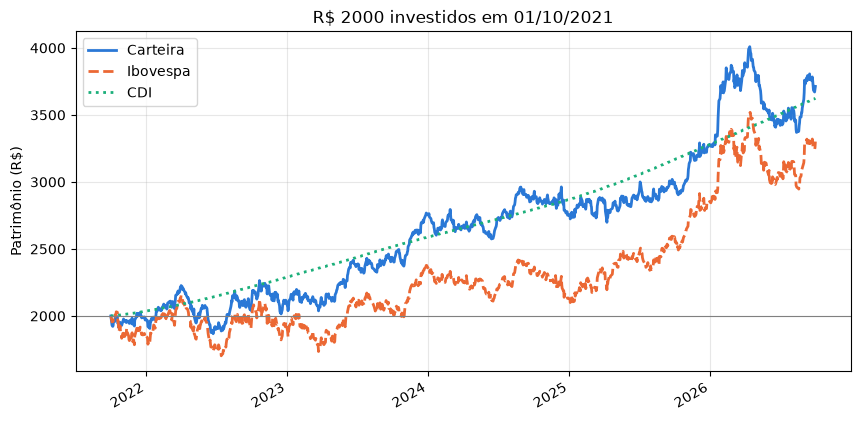

In [16]:
ax = curvas.plot(
    figsize=(10, 5),
    style=["-", "--", ":"],                     # linhas diferentes: lê-se até sem cor
    color=["#2a78d6", "#eb6834", "#1baf7a"],    # azul, laranja e verde-água
    linewidth=2,
    title=f"R$ {CAPITAL} investidos em {inicio_bc}",
)
ax.axhline(CAPITAL, color="gray", linewidth=0.8)  # o capital inicial, como referência
ax.set_ylabel("Patrimônio (R$)")
ax.set_xlabel("")
ax.grid(alpha=0.3)
plt.show()

**O que o gráfico mostra.** **[Preencher depois de rodar: quem terminou na frente, em que momentos a ordem entre as curvas mudou e quais foram os períodos de queda mais forte.]**

### Bloco 19 · Cada ação no período

A carteira é uma média, e médias escondem os extremos. Este gráfico mostra o retorno de cada uma das 10 ações no período, em barras horizontais ordenadas da pior para a melhor.

- `crescimento.iloc[-1]` pega a última linha da tabela de crescimento: quanto R\\$ 1 virou em cada ação no último dia. Subtraindo 1 e multiplicando por 100, temos o retorno de cada ação em %.
- `sort_values()` ordena as ações do menor para o maior retorno.
- A linha azul tracejada marca o retorno da carteira, na mesma cor que ela tem no gráfico anterior. A linha preta marca o zero.

Um fato curioso, que decorre da fórmula do bloco 3: numa carteira que começou com o mesmo valor em cada ação e nunca foi rebalanceada, o retorno do período é exatamente a média simples dos 10 retornos.

> **O que esperar:** 10 barras cinza, uma por ação, e a linha da carteira entre a melhor e a pior.

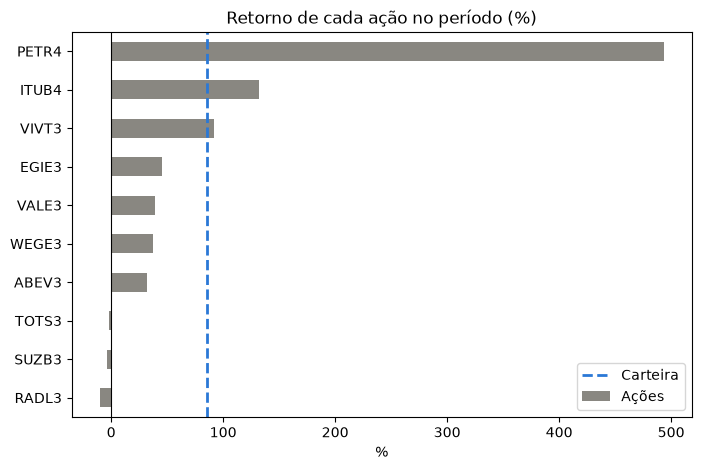

In [17]:
retorno_acoes = (crescimento.iloc[-1] - 1) * 100
retorno_carteira = (carteira.iloc[-1] / CAPITAL - 1) * 100

ax = retorno_acoes.sort_values().plot.barh(figsize=(8, 5), color="#898781", label="Ações")
ax.axvline(retorno_carteira, color="#2a78d6", linestyle="--", linewidth=2, label="Carteira")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Retorno de cada ação no período (%)")
ax.set_xlabel("%")
ax.set_ylabel("")
ax.legend()
plt.show()

**O que as barras mostram.** **[Preencher: qual ação foi a melhor, qual foi a pior e quantas ficaram acima da carteira.]**

### Bloco 20 · A tabela final

Para fechar, a resposta em números. Criamos uma tabela vazia, `pd.DataFrame(index=curvas.columns)`, com uma linha para cada alternativa, e preenchemos coluna por coluna:

- **Valor final:** a última linha de `curvas`, pega com `.iloc[-1]`.
- **Retorno no período:** o valor final dividido pelo capital, menos 1, vezes 100.

O `.round(2)` arredonda a exibição para duas casas decimais.

> **O que esperar:** uma tabela com três linhas (Carteira, Ibovespa e CDI) e duas colunas (valor final e retorno).

In [18]:
resumo = pd.DataFrame(index=curvas.columns)
resumo["Valor final (R$)"] = curvas.iloc[-1]
resumo["Retorno no período (%)"] = (curvas.iloc[-1] / CAPITAL - 1) * 100
resumo.round(2)

,Valor final (R$),Retorno no período (%)
Carteira,3712.68,85.63
Ibovespa,3300.97,65.05
CDI,3624.31,81.22


**A resposta em números.** **[Preencher com os números.]**

## Parte 5 · Validação

### Bloco 21 · A carteira é mesmo a soma das 10 partes?

No bloco 14, usamos a média dos fatores como atalho para somar as 10 partes de R\\$ 200. Agora conferimos pelo caminho longo: calculamos quanto cada parte de R\\$ 200 virou e somamos as 10. Os dois números precisam ser iguais.

> **O que esperar:** dois valores idênticos.

In [19]:
mini_carteiras = crescimento.iloc[-1] * (CAPITAL / len(ACOES))
print("Soma das 10 mini-carteiras: R$", round(mini_carteiras.sum(), 2))
print("Valor final da carteira:    R$", round(carteira.iloc[-1], 2))

Soma das 10 mini-carteiras: R$ 3712.68
Valor final da carteira:    R$ 3712.68


### Bloco 22 · As três curvas largam juntas?

Uma comparação só é justa se todos largam do mesmo ponto. A primeira linha de `curvas` precisa mostrar R\\$ 2.000 nas três colunas, na data de 01/10/2021.

> **O que esperar:** `Carteira 2000.0`, `Ibovespa 2000.0` e `CDI 2000.0`, com a data `2021-10-01` no rodapé.

In [20]:
curvas.iloc[0]

Carteira    2000.0
Ibovespa    2000.0
CDI         2000.0
Name: 2021-10-01 00:00:00, dtype: float64

### Bloco 23 · O CDI confere com o Banco Central?

O Banco Central tem uma ferramenta pública, a **Calculadora do Cidadão**, que corrige valores pelo CDI. Calculamos o CDI acumulado no período e comparamos com o resultado da calculadora: na opção "Correção de valores", aba "CDI", informe R\\$ 2.000, data inicial 01/10/2021 e data final 30/09/2026. A diferença deve ser de centavos, pela convenção de qual dia entra na conta (bloco 16).

> **O que esperar:** o CDI acumulado no período, em %, e o valor final em reais.

In [21]:
cdi_periodo = (cdi_acumulado.iloc[-1] / cdi_acumulado.iloc[0] - 1) * 100
print("CDI acumulado no período:", round(cdi_periodo, 2), "%")
print("R$", CAPITAL, "no CDI viraram R$", round(cdi_reais.iloc[-1], 2))

CDI acumulado no período: 81.22 %
R$ 2000 no CDI viraram R$ 3624.31


**Conferência com a Calculadora do Cidadão.** **[Preencher: o valor da Calculadora do Cidadão e a diferença encontrada.]**

### Bloco 24 · Conferência das ações com outra fonte

O Yahoo Finance não é uma fonte oficial, e os ajustes por proventos de ações brasileiras às vezes têm falhas. Escolha duas ações e compare o retorno do período com outra fonte que calcule a rentabilidade com proventos reinvestidos, como os sites de análise de ações. Diferenças pequenas são normais, porque cada fonte trata os proventos de um jeito. Uma diferença grande indica problema nos dados daquela ação.

**[Preencher: ações conferidas, fonte usada e diferença encontrada.]**

## Parte 6 · Interpretação

### Bloco 25 · O que os números dizem

**[Texto a completar com os resultados reais.]**

Nos cinco anos analisados, os R\\$ 2.000 da carteira viraram **R\\$ [valor]**, um retorno de **[x]%**. No mesmo período, o Ibovespa transformou R\\$ 2.000 em **R\\$ [valor]** ([x]%), e o CDI, em **R\\$ [valor]** ([x]%).

**[Escolha a frase que corresponde ao resultado:]** A carteira ganhou dos dois. / A carteira ganhou do Ibovespa, mas perdeu para o CDI. / A carteira perdeu para o Ibovespa, mas ganhou do CDI. / A carteira perdeu para os dois.

Perguntas que orientam a interpretação:

1. **Quem ganhou, e por quanto?** Diferenças de poucos pontos percentuais em cinco anos podem mudar com outra data de início.
2. **O caminho foi parecido com o resultado?** Olhe o gráfico do bloco 18: houve períodos em que a ordem entre as curvas era outra?
3. **Quanto da carteira veio de poucas ações?** Olhe o bloco 19: a melhor e a pior ação puxaram o resultado em direções opostas.
4. **O que o CDI ensina?** Ele é o custo de oportunidade: o que se ganharia sem correr o risco de oscilação. Investir em ações só compensa, no longo prazo, se o retorno for maior que o do CDI. O quanto maior ele precisa ser, para compensar o risco, é o tema da próxima aula.

## Parte 7 · Limitações

### Bloco 26 · O que esta análise não mostra

- **O passado não garante o futuro.** Os mesmos 10 papéis, em outros cinco anos, podem ter um resultado muito diferente.
- **Escolha feita com o conhecimento de hoje.** As empresas foram escolhidas em 2026, entre as que são grandes e conhecidas hoje. Quem investia em 2021 não sabia quais empresas estariam bem cinco anos depois. Esse viés de seleção pode deixar a carteira melhor do que seria uma escolha feita de verdade em 2021.
- **Comparação bruta.** Não entraram custos de corretagem, taxas da bolsa nem impostos, que incidem de forma diferente em ações e em renda fixa. Na vida real, aplicações atreladas ao CDI, como os CDBs, pagam um percentual do CDI e têm imposto de renda.
- **Frações de ação.** R\\$ 200 nem sempre compram um número inteiro de ações. Na prática, a compra seria feita no mercado fracionário, de uma em uma ação, e sobraria algum troco.
- **Ibovespa sem custos.** O índice não pode ser comprado diretamente; os fundos que o replicam cobram taxa.
- **Sensibilidade à data de início.** Outro ponto de partida pode mudar a conclusão (exercício 2).
- **Qualidade dos dados.** O Yahoo Finance pode ter falhas, por isso a conferência do bloco 24.

## Parte 8 · Exercícios

### Bloco 27 · Para praticar

1. **Outra carteira.** Troque as ações da lista `ACOES` por outras 10 e rode o notebook inteiro (menu Run → Run All Cells).
2. **Outra data de início.** Mude `DATA_INICIO` para 2019 ou para 2023. A conclusão continua a mesma? Lembre-se de que a API do Banco Central aceita no máximo 10 anos por consulta.
3. **Sem a campeã.** Retire da lista a ação de melhor desempenho e rode de novo. O que acontece com a carteira? O que isso diz sobre escolher ações olhando o passado?
4. **Carteira menor.** Use só 5 ações. A carteira fica mais perto ou mais longe da melhor e da pior ação?
5. **Melhor e pior momento.** Descubra em que dia a carteira esteve mais acima do CDI e em que dia esteve mais abaixo. Dica: calcule `curvas["Carteira"] - curvas["CDI"]` e use `.idxmax()` e `.idxmin()`, que devolvem a data do maior e do menor valor.

## Resumo

### Bloco 28 · O que aprendemos

**Em finanças:**

- Rentabilidade se mede com o preço ajustado, que considera proventos e desdobramentos.
- Um resultado só tem significado quando comparado a um benchmark: o Ibovespa para ações e o CDI para renda fixa.
- R\\$ 1 investido vira $P_t / P_0$; uma carteira com pesos iguais vale o capital vezes a média desses fatores.
- O CDI cresce por juros compostos: os fatores diários são multiplicados, não somados.

**Em Python:**

- Bibliotecas são instaladas com `%pip` e carregadas com `import`.
- Listas guardam vários valores em ordem; f-strings colocam variáveis dentro de textos.
- DataFrame é uma tabela e Series é uma coluna; `.loc` seleciona por rótulo e `.iloc`, por posição.
- O pandas faz contas com a tabela inteira de uma vez.
- Dados vindos de fora precisam ser inspecionados (`isna`), tratados (`ffill`) e convertidos (`to_datetime`, `astype`).
- `cumprod` acumula produtos; `concat` junta séries pelas datas; `.plot` desenha gráficos.

## Gancho para a aula 2

### Bloco 29 · Próxima aula

O valor final conta só o fim da história. **[Ajustar ao resultado: no meio do caminho, a carteira chegou a ficar X% abaixo do seu melhor momento.]** Você teria aguentado segurar? Duas carteiras podem terminar no mesmo lugar e dar experiências completamente diferentes no caminho.

Na próxima aula, vamos medir isso: quanto risco a carteira correu para entregar esse retorno. E vamos aprender a escrever funções, para calcular cada medida uma vez e reutilizá-la nas três curvas e nas 10 ações.

## Glossário da aula

| Termo | Significado |
|---|---|
| Ação | Fração do capital de uma empresa negociada na bolsa |
| Ticker | Código da ação na bolsa (ex.: ITUB4) |
| Provento | Dinheiro distribuído pela empresa ao acionista, como dividendos |
| Preço ajustado | Histórico de preços recalculado para incluir proventos e desdobramentos |
| Benchmark | Referência de comparação para um investimento |
| Ibovespa | Principal índice da B3; carteira teórica das ações mais negociadas, com retorno total |
| CDI | Taxa dos empréstimos de um dia entre bancos; referência da renda fixa |
| Juros compostos | Rendimento que incide sobre o rendimento anterior |
| API | Endereço da internet que devolve dados para programas |
| JSON | Formato de texto para troca de dados entre sistemas |
| DataFrame | Tabela do pandas |
| Series | Uma coluna do pandas, com índice |
| Índice | Rótulos das linhas de uma tabela; aqui, as datas |
| NaN | Valor ausente (*not a number*) |

---

*Python Finance Lab · Conteúdo exclusivamente educacional. Não constitui recomendação de investimento.*